In [3]:
# Посмотрим, какие именно параметры больше всего влияют на поломку оборудования
import pandas as pd

feature_importances = pd.DataFrame(
    model.feature_importances_,
    index=X.columns,
    columns=['Важность параметра']
).sort_values(by='Важность параметра', ascending=False)

print("Что больше всего пугает модель (важность датчиков):")
display(feature_importances)


Что больше всего пугает модель (важность датчиков):


,Важность параметра
vibration,0.455828
temperature,0.375037
pressure,0.169135


In [6]:
# Функция для проверки состояния воображаемого станка
def check_equipment_status(vibration, temperature, pressure):
    # Собираем данные в табличку для модели
    new_data = pd.DataFrame({
        'vibration': [vibration],
        'temperature': [temperature],
        'pressure': [pressure]
    })
    
    # Модель делает предсказание (0 — штатно, 1 — риск отказа)
    prediction = model.predict(new_data)[0]
    
    # Выводим красивый и понятный ответ для инженера
    print("--- Результат диагностики станка ---")
    if prediction == 1:
        print("⚠️ Внимание! Высокий риск отказа оборудования! Рекомендуется срочный осмотр узла.")
    else:
        print("✅ Оборудование работает штатно. Показатели в норме.")

# ---- ПРОВЕРИМ РАБОТУ СИСТЕМЫ НА ПРИМЕРЕ ----

# Пример 1: Нормальные показатели
print("Случай 1 (штатные показатели):")
check_equipment_status(vibration=0.9, temperature=62.0, pressure=2.1)

print("\n" + "="*40 + "\n")

# Пример 2: Опасные показатели (рост вибрации и температуры)
print("Случай 2 (аномальные показатели):")
check_equipment_status(vibration=1.5, temperature=76.0, pressure=2.5)

Случай 1 (штатные показатели):
--- Результат диагностики станка ---
✅ Оборудование работает штатно. Показатели в норме.


Случай 2 (аномальные показатели):
--- Результат диагностики станка ---
⚠️ Внимание! Высокий риск отказа оборудования! Рекомендуется срочный осмотр узла.


In [ ]:
# Проверяем, существует ли модель, и выводим метрики
try:
    # Пробуем использовать стандартное имя 'model' или ищем альтернативы
    current_model = model if 'model' in globals() else rfc
    current_X_test = X_test if 'X_test' in globals() else X_val
    current_y_test = y_test if 'y_test' in globals() else y_val
    
    y_pred = current_model.predict(current_X_test)
    
    print("--- Отчет о классификации (Classification Report) ---")
    print(classification_report(current_y_test, y_pred))
    
    # Строим матрицу ошибок
    plt.figure(figsize=(6, 5))
    cm = confusion_matrix(current_y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Штатно (0)', 'Отказ (1)'],
                yticklabels=['Штатно (0)', 'Отказ (1)'])
    plt.title('Матрица ошибок (Confusion Matrix)', fontsize=13, fontweight='bold', pad=12)
    plt.xlabel('Прогноз модели', fontsize=11)
    plt.ylabel('Реальное состояние', fontsize=11)
    plt.tight_layout()
    plt.show()
    
except NameError as e:
    print(f"⚠️ Переменная не найдена: {e}. Убедись, что ты предварительно запустил ячейку с обучением модели и разделением данных (train_test_split).")
    

Шаг 1: Генерация многоцикличных данных с чередованием штатной работы и отказов...
Шаг 2: Расчет скользящих средних и дельт внутри циклов...
Размер обучающей выборки: 700, тестовой: 300
Шаг 4: Обучение Random Forest Classifier...

--- Шаг 5: Результаты оценки качества модели ---
              precision    recall  f1-score   support

  Штатно (0)       1.00      1.00      1.00       210
   Отказ (1)       0.99      0.99      0.99        90

    accuracy                           0.99       300
   macro avg       0.99      0.99      0.99       300
weighted avg       0.99      0.99      0.99       300



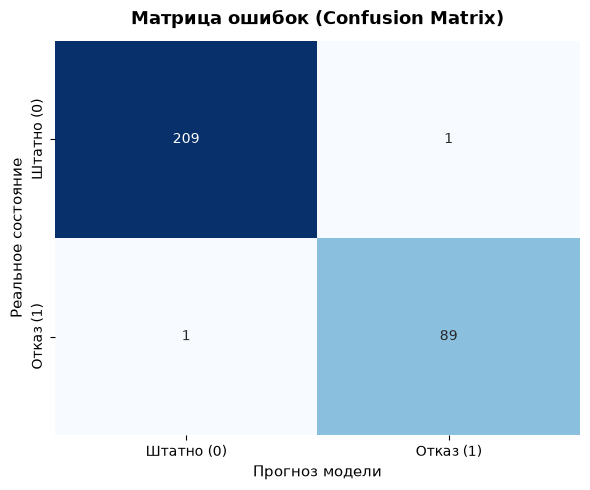

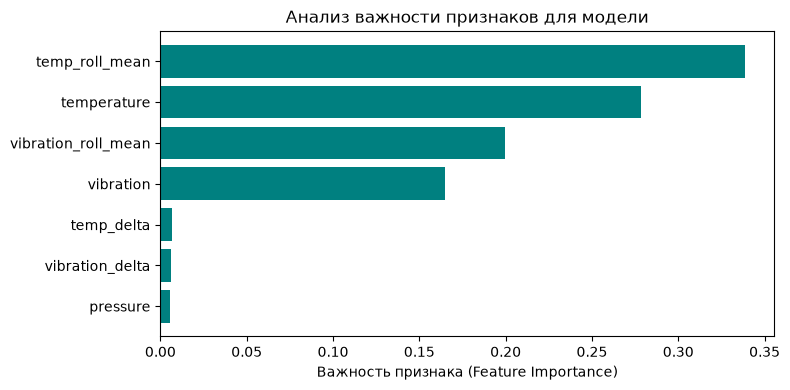

In [4]:
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Устанавливаем фиксированный random_state для воспроизводимости
np.random.seed(42)

# --- ШАГ 1: ГЕНЕРАЦИЯ ДАННЫХ С НЕСКОЛЬКИМИ ЦИКЛАМИ РАБОТЫ ---
print("Шаг 1: Генерация многоцикличных данных с чередованием штатной работы и отказов...")

n_cycles = 10         # Количество циклов работы оборудования (пусков / смен)
steps_per_cycle = 100  # Шагов (часов) в каждом цикле
total_steps = n_cycles * steps_per_cycle

time_index = pd.date_range(start="2026-01-01", periods=total_steps, freq="h")

vibration_list = []
temperature_list = []
pressure_list = []
failure_list = []
cycle_id_list = []

for cycle in range(n_cycles):
    # Внутри каждого цикла параметры плавно нарастают от нормы к аварийным значениям
    vib = np.linspace(0.8, 1.35, steps_per_cycle) + np.random.normal(0, 0.04, steps_per_cycle)
    temp = np.linspace(55.0, 74.0, steps_per_cycle) + np.random.normal(0, 0.8, steps_per_cycle)
    pres = np.random.normal(2.0, 0.1, steps_per_cycle)
    
    # Отказ наступает в последней трети каждого цикла (предаварийное состояние)
    fail = np.zeros(steps_per_cycle, dtype=int)
    fail[int(steps_per_cycle * 0.7):] = 1 
    
    vibration_list.extend(vib)
    temperature_list.extend(temp)
    pressure_list.extend(pres)
    failure_list.extend(fail)
    cycle_id_list.extend([cycle] * steps_per_cycle)

df = pd.DataFrame({
    'timestamp': time_index,
    'cycle_id': cycle_id_list,
    'vibration': vibration_list,
    'temperature': temperature_list,
    'pressure': pressure_list,
    'failure': failure_list
})

# --- ШАГ 2: FEATURE ENGINEERING С УЧЕТОМ ГРАНИЦ ЦИКЛОВ ---
print("Шаг 2: Расчет скользящих средних и дельт внутри циклов...")

# Считаем скользящие средние отдельно для каждого цикла (group_by), чтобы окна не «перетекали» между пусками
df['vibration_roll_mean'] = df.groupby('cycle_id')['vibration'].transform(lambda x: x.rolling(window=5, min_periods=1).mean())
df['temp_roll_mean'] = df.groupby('cycle_id')['temperature'].transform(lambda x: x.rolling(window=5, min_periods=1).mean())

df['vibration_delta'] = df.groupby('cycle_id')['vibration'].diff().fillna(0)
df['temp_delta'] = df.groupby('cycle_id')['temperature'].diff().fillna(0)

features = ['vibration', 'temperature', 'pressure', 'vibration_roll_mean', 'temp_roll_mean', 'vibration_delta', 'temp_delta']
X = df[features]
y = df['failure']

# --- ШАГ 3: РАЗДЕЛЕНИЕ ВЫБОРОК ПО ЦИКЛАМ ---
# Обучаем модель на первых 7 циклах, а тестируем на последних 3 циклах
train_cycles = range(7)
train_mask = df['cycle_id'].isin(train_cycles)

X_train, X_test = X[train_mask], X[~train_mask]
y_train, y_test = y[train_mask], y[~train_mask]

print(f"Размер обучающей выборки: {len(X_train)}, тестовой: {len(X_test)}")

# --- ШАГ 4: ОБУЧЕНИЕ МОДЕЛИ ---
print("Шаг 4: Обучение Random Forest Classifier...")
model = RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced')
model.fit(X_train, y_train)

# --- ШАГ 5: ОЦЕНКА КАЧЕСТВА И МЕТРИКИ ---
print("\n--- Шаг 5: Результаты оценки качества модели ---")
y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred, target_names=['Штатно (0)', 'Отказ (1)']))

plt.figure(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Штатно (0)', 'Отказ (1)'],
            yticklabels=['Штатно (0)', 'Отказ (1)'])
plt.title('Матрица ошибок (Confusion Matrix)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Прогноз модели', fontsize=11)
plt.ylabel('Реальное состояние', fontsize=11)
plt.tight_layout()
plt.show()

# --- ШАГ 6: АНАЛИЗ ВАЖНОСТИ ПРИЗНАКОВ (XAI) ---
plt.figure(figsize=(8, 4))
importances = model.feature_importances_
sorted_idx = np.argsort(importances)

plt.barh(range(len(sorted_idx)), importances[sorted_idx], color='teal')
plt.yticks(range(len(sorted_idx)), [features[i] for i in sorted_idx])
plt.xlabel('Важность признака (Feature Importance)')
plt.title('Анализ важности признаков для модели')
plt.tight_layout()
plt.show()